## Wstęp do Uczenia Maszynowego

#### Laboratorium 05


### Zakres laboratorium


- przygotowanie danych: wartości odstające i braki danych
- `Pipeline` i `ColumnTransformer`
- reprodukowalność podziałów danych i eksperymentów

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


In [57]:
df = pd.read_csv("titanic.csv")
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,survived
0,1.0,"Allen, Miss. Elisabeth Walton",female,29.0000,0.0,0.0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1
1,1.0,"Allison, Master. Hudson Trevor",male,0.9167,1.0,2.0,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",1
2,1.0,"Allison, Miss. Helen Loraine",female,2.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0
3,1.0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0
4,1.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,3.0,"Zabour, Miss. Hileni",female,14.5000,1.0,0.0,2665,14.4542,NaN,C,NaN,328.0,NaN,0
1305,3.0,"Zabour, Miss. Thamine",female,NaN,1.0,0.0,2665,14.4542,NaN,C,NaN,NaN,NaN,0
1306,3.0,"Zakarian, Mr. Mapriededer",male,26.5000,0.0,0.0,2656,7.2250,NaN,C,NaN,304.0,NaN,0
1307,3.0,"Zakarian, Mr. Ortin",male,27.0000,0.0,0.0,2670,7.2250,NaN,C,NaN,NaN,NaN,0


| Nazwa kolumny | Opis                                            |
|---------------|-------------------------------------------------|
| pclass        | Klasa biletu                                    |
| name          | Imię i nazwisko pasażera                        |
| sex           | Płeć pasażera                                   |
| age           | Wiek pasażera w latach                          |
| sibsp         | Liczba rodzeństwa / współmałżonków na pokładzie |
| parch         | Liczba rodziców / dzieci na pokładzie           |
| ticket        | Numer biletu                                    |
| fare          | Cena biletu (w funtach szterlingach z 1912 r.)  |
| cabin         | Numer kabiny                                    |
| embarked      | Port, w którym pasażer wsiadł na pokład         |
| boat          | Numer łodzi ratunkowej (dla ocalałych)          |
| body          | Numer odnalezionego ciała (dla zmarłych)        |
| home.dest     | Dom / Miejsce docelowe pasażera                 |
| survived      | Status przeżycia                                |

In [58]:
y = df.survived
X = df.drop(["survived"], axis = 1)

### 1. Przygotowanie danych

#### Wartości odstające

Wartość skrajna nie musi być błędem. Najpierw wykrywamy takie obserwacje i sprawdzamy ich znaczenie w kontekście problemu; usuwamy je lub przekształcamy dopiero wtedy, gdy mamy ku temu uzasadnienie.


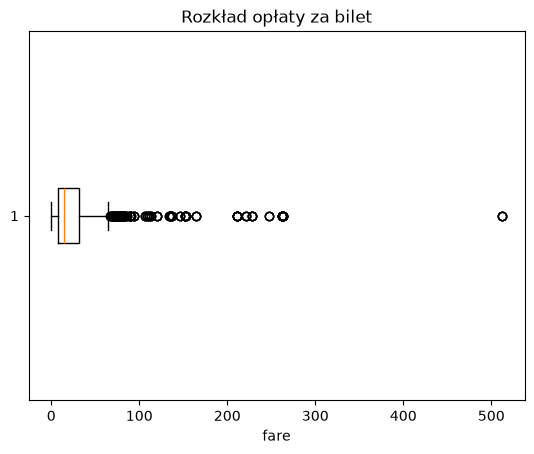

Próg 1,5 IQR: 66.34


,pclass,fare,name
49,1.0,512.3292,"Cardeza, Mr. Thomas Drake Martinez"
50,1.0,512.3292,"Cardeza, Mrs. James Warburton Martinez (Charlo..."
183,1.0,512.3292,"Lesurer, Mr. Gustave J"
302,1.0,512.3292,"Ward, Miss. Anna"
114,1.0,263.0000,"Fortune, Mr. Charles Alexander"


In [59]:
# Rozkład opłaty za bilet. Boxplot wskazuje obserwacje daleko od pozostałych,
# ale sam nie rozstrzyga, czy są one błędami.
fig, ax = plt.subplots()
ax.boxplot(df["fare"].dropna(), orientation="horizontal")
ax.set_xlabel("fare")
ax.set_title("Rozkład opłaty za bilet")
plt.show()

q1, q3 = df["fare"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
fare_extreme = df.loc[df["fare"] > upper_fence, ["pclass", "fare", "name"]]
print(f"Próg 1,5 IQR: {upper_fence:.2f}")
fare_extreme.sort_values("fare", ascending=False).head()


W tym zbiorze wysokie wartości `fare` odpowiadają drogim biletom, więc nie traktujemy ich automatycznie jako błędów i ich nie usuwamy. Gdyby celem było modelowanie wrażliwe na silnie skośny rozkład, można byłoby później rozważyć np. transformację `log1p(fare)` $\Big(ln(1+x)\Big)$.

#### Braki danych

Braki można uzupełniać różnie zależnie od typu zmiennej, np. średnią dla cech numerycznych albo najczęstszą kategorią dla cech kategorycznych. Ważne, aby parametry imputacji wyznaczać tylko na danych treningowych — `Pipeline` zapewnia to automatycznie.


-----
##### *Zadanie 1*

Przyjrzyj się danym `titanic`. Korzystając z informacji o typach, brakach i rozkładach, podziel kolumny na: przydatne bez zmian, wymagające przygotowania oraz takie, które należy usunąć.


In [60]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   float64
 1   name       1309 non-null   str    
 2   sex        1309 non-null   str    
 3   age        1046 non-null   float64
 4   sibsp      1309 non-null   float64
 5   parch      1309 non-null   float64
 6   ticket     1309 non-null   str    
 7   fare       1308 non-null   float64
 8   cabin      295 non-null    str    
 9   embarked   1307 non-null   str    
 10  boat       486 non-null    str    
 11  body       121 non-null    float64
 12  home.dest  745 non-null    str    
dtypes: float64(6), str(7)
memory usage: 133.1 KB


In [61]:
X[[c for c, d in zip(X.columns, X.dtypes) if d == "str"]].value_counts()

name                                           sex     ticket         cabin    embarked  boat  home.dest                      
Allen, Miss. Elisabeth Walton                  female  24160          B5       S         2     St Louis, MO                       1
Allison, Master. Hudson Trevor                 male    113781         C22 C26  S         11    Montreal, PQ / Chesterville, ON    1
Anderson, Mr. Harry                            male    19952          E12      S         3     New York, NY                       1
Andrews, Miss. Kornelia Theodosia              female  13502          D7       S         10    Hudson, NY                         1
Appleton, Mrs. Edward Dale (Charlotte Lamson)  female  11769          C101     S         D     Bayside, Queens, NY                1
                                                                                                                                 ..
Nourney, Mr. Alfred ('Baron von Drachstedt')   male    SC/PARIS 2166  D38      C 

In [62]:
{c: X[c].unique() for c, d in zip(X.columns, X.dtypes) if d == "str"}

{'name': <StringArray>
 [                  'Allen, Miss. Elisabeth Walton',
                   'Allison, Master. Hudson Trevor',
                     'Allison, Miss. Helen Loraine',
             'Allison, Mr. Hudson Joshua Creighton',
  'Allison, Mrs. Hudson J C (Bessie Waldo Daniels)',
                              'Anderson, Mr. Harry',
                'Andrews, Miss. Kornelia Theodosia',
                           'Andrews, Mr. Thomas Jr',
    'Appleton, Mrs. Edward Dale (Charlotte Lamson)',
                          'Artagaveytia, Mr. Ramon',
  ...
                              'Yasbeck, Mr. Antoni',
          'Yasbeck, Mrs. Antoni (Selini Alexander)',
                             'Youseff, Mr. Gerious',
                                'Yousif, Mr. Wazli',
                            'Yousseff, Mr. Gerious',
                             'Zabour, Miss. Hileni',
                            'Zabour, Miss. Thamine',
                        'Zakarian, Mr. Mapriededer',
                 

array([[<Axes: title={'center': 'pclass'}>,
        <Axes: title={'center': 'age'}>],
       [<Axes: title={'center': 'sibsp'}>,
        <Axes: title={'center': 'parch'}>],
       [<Axes: title={'center': 'fare'}>,
        <Axes: title={'center': 'body'}>]], dtype=object)

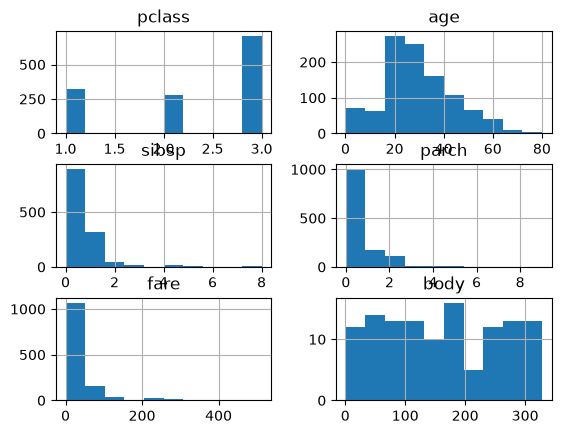

In [63]:
X.hist()

#### Decyzje dotyczące kolumn

- przydatne bez zmian:
- wymagające przygotowania:
- należy usunąć:

In [64]:
# TODO: wybierz kolumny do usunięcia zgodnie z analizą powyżej.
# Zwróć szczególną uwagę na zmienne powodujące leakage: boat i body.
columns_to_drop = ["boat", "body", "ticket", "cabin", "name", "home.dest"]
X = X.drop(columns=columns_to_drop)


-----
##### *Zadanie 2*

Przygotuj listy `numerical_features` i `categorical_features`, zawierające odpowiednio nazwy kolumn numerycznych i kategorycznych. Uruchom kod i sprawdź, czy odpowiadają decyzjom z poprzedniego zadania.


In [65]:
# TODO: utwórz listy kolumn numerycznych i kategorycznych na podstawie ich typów.
numerical_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

print("Cechy numeryczne:", numerical_features)
print("Cechy kategoryczne:", categorical_features)


Cechy numeryczne: ['pclass', 'age', 'sibsp', 'parch', 'fare']
Cechy kategoryczne: ['sex', 'embarked']


-----
##### *Zadanie 2 z gwiazdką*
Jak wykorzystując informację o typach kolumn podzielić je na numeryczne i kategoryczne?


#### Pipeline dla cech numerycznych

Dla cech numerycznych najpierw uzupełniamy braki średnią, a następnie standaryzujemy wartości. Drzewo nie wymaga skalowania, ale ten sam etap będzie można połączyć później z modelami wrażliwymi na skalę cech.


In [66]:
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])


-----
##### *Zadanie 3*

Przygotuj `Pipeline` dla zmiennych kategorycznych. Użyj `SimpleImputer()` ze strategią wyboru najczęstszej kategorii oraz `OneHotEncoder()` z ignorowaniem nieznanych kategorii.

https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

In [67]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])


#### Połączenie przygotowania danych z modelem

`ColumnTransformer` stosuje właściwy pipeline do każdej grupy kolumn. Następnie cały etap przygotowania łączymy z drzewem w jeden `Pipeline`.

https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html


In [68]:
# TODO: połącz oba pipeline'y w ColumnTransformer.
preprocessor = ColumnTransformer([
    ("numerical", numerical_transformer, numerical_features),
    # TODO:
    ("categorical", categorical_transformer, categorical_features),
])

# TODO: połącz preprocessor z drzewem decyzyjnym w jeden Pipeline.
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier())
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
pipeline.fit(X_train, y_train)

print("Accuracy na zbiorze treningowym:", round(pipeline.score(X_train, y_train), 3))
print("Accuracy na zbiorze testowym:", round(pipeline.score(X_test, y_test), 3))


Accuracy na zbiorze treningowym: 0.971
Accuracy na zbiorze testowym: 0.763


Jeżeli wynik na zbiorze treningowym jest wyraźnie wyższy niż na testowym, może to wskazywać na przeuczenie. W dalszej części laboratorium dostroimy złożoność drzewa za pomocą walidacji krzyżowej.


-----
##### *Zadanie 4*

Wczytaj zbiór danych `pima.csv`. Narysuj rozkład `BloodPressure` osobno dla klas `Outcome` i zastanów się, co mogą oznaczać wartości równe 0.


In [69]:
pima = pd.read_csv("pima.csv")
y = pima["Outcome"]
X = pima.drop(columns="Outcome")


Outcome
0    [[Axes(0.125,0.666111;0.215278x0.213889), Axes...
1    [[Axes(0.125,0.666111;0.215278x0.213889), Axes...
dtype: object

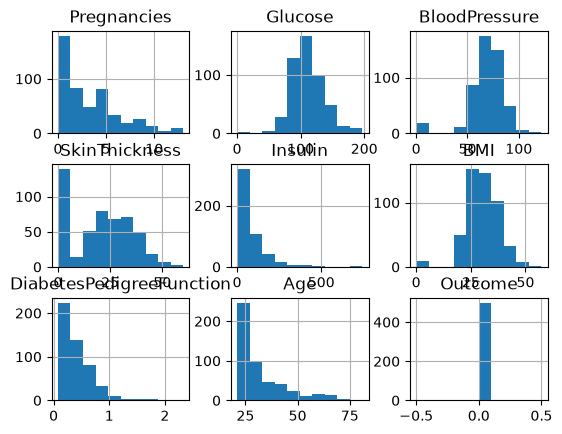

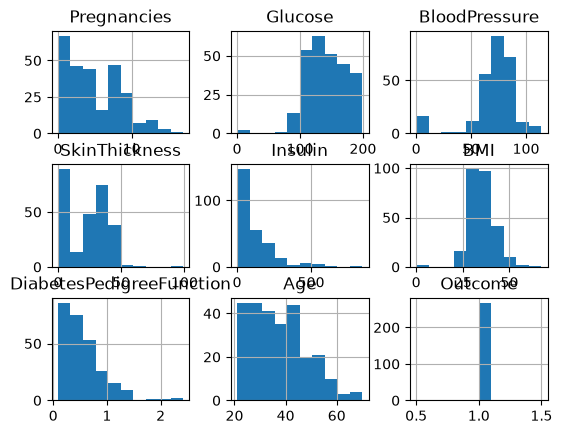

In [70]:
pima.groupby("Outcome").hist()

-----
##### *Zadanie 5*

a) Zastąp wartości 0 zmiennej `BloodPressure` brakami danych. Podziel dane na zbiór treningowy i testowy w proporcji 7:3. Przygotuj `Pipeline` z imputacją średnią i drzewem decyzyjnym. Oblicz `accuracy` na zbiorze treningowym i testowym.

b) Przeprowadź optymalizację hiperparametrów pipeline'u za pomocą `GridSearchCV` z 3-krotną walidacją krzyżową. Rozważ `max_depth` od 5 do 12 oraz `min_samples_leaf` od 3 do 9.

c) Podaj najlepsze parametry i najlepszą wartość accuracy w CV. Na zbiorze testowym porównaj accuracy oraz ROC AUC dostrojonego i bazowego pipeline'u.

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://scikit-learn.org/stable/modules/grid_search.html

In [71]:
# TODO: zastąp zera w BloodPressure wartością np.nan.
X.loc[X["BloodPressure"] == 0, "BloodPressure"] = np.nan

In [72]:
pipeline = Pipeline([
    # TODO: uzupełnij braki średnią
    ("imputer", SimpleImputer(strategy="mean")),
    # TODO: dodaj klasyfikator drzewa decyzyjnego
    ("tree", DecisionTreeClassifier()),
])


In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
pipeline.fit(X_train, y_train)

print("Accuracy na zbiorze treningowym:", round(pipeline.score(X_train, y_train), 3))
print("Accuracy na zbiorze testowym:", round(pipeline.score(X_test, y_test), 3))


Accuracy na zbiorze treningowym: 1.0
Accuracy na zbiorze testowym: 0.701


In [74]:
# Siatka wartości hiperparametrów, które chcemy porównać.
params = {
    "tree__max_depth": np.arange(3, 20, 2), # TODO: wybierz zakres,
    "tree__min_samples_leaf": np.arange(5, 100, 5), # TODO: wybierz zakres,
}

# Dzielimy wyłącznie zbiór treningowy na trzy foldy.
# Używamy zwykłego KFold; dla klasyfikatora GridSearchCV domyślnie wybrałby StratifiedKFold.
cv_3 = KFold(n_splits=3, shuffle=True, random_state=42)

# GridSearchCV dopasuje pipeline dla każdej kombinacji parametrów i każdego foldu,
# a następnie wybierze konfigurację o najwyższej średniej accuracy w CV.
grid_pipeline = GridSearchCV(
    estimator=pipeline,
    param_grid=params,
    cv=cv_3,
    scoring="accuracy",
)


In [75]:
grid_pipeline.fit(X_train, y_train)

selected_acc = grid_pipeline.score(X_test, y_test) # TODO: oblicz accuracy z modelu z GridSearch (podpunkt b)) 
baseline_acc = pipeline.score(X_test, y_test) # TODO: oblicz accuracy z modelu bez GridSearch (podpunkt a)) 
selected_auc = roc_auc_score(y_test, grid_pipeline.predict_proba(X_test)[:, 1]) # TODO: oblicz AUC
baseline_auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1]) # TODO: oblicz AUC

print("Najlepsze parametry:", grid_pipeline.best_params_) # TODO: wskaż najlepsze parametry z GridSearch
print("Najlepsza accuracy w CV:", round(grid_pipeline.score(X_test, y_test), 3)) # TODO: wskaż wartość accuracy dla najlepszej konfiguracji hiperparametrów
print("Accuracy dostrojonego modelu na teście:", round(selected_acc, 3))
print("ROC AUC dostrojonego modelu na teście:", round(selected_auc, 3))
print("Accuracy bazowego modelu na teście:", round(baseline_acc, 3))
print("ROC AUC bazowego modelu na teście:", round(baseline_auc, 3))


Najlepsze parametry: {'tree__max_depth': np.int64(5), 'tree__min_samples_leaf': np.int64(35)}
Najlepsza accuracy w CV: 0.766
Accuracy dostrojonego modelu na teście: 0.766
ROC AUC dostrojonego modelu na teście: 0.787
Accuracy bazowego modelu na teście: 0.701
ROC AUC bazowego modelu na teście: 0.692


### 2. Reprodukowalność eksperymentów

Losowy podział danych może zmienić nie tylko konkretne obserwacje w zbiorze testowym, ale też rozkład zmiennej docelowej i cech. Ustawienie `random_state` pozwala odtworzyć konkretny eksperyment.


#### Przykład: wpływ losowego podziału danych

Porównajmy kilka podziałów danych `titanic`. Ten sam `random_state` odtwarza identyczny zbiór testowy, ale różne wartości seeda prowadzą do innych obserwacji i nieco innych rozkładów zmiennych.



Ten sam random_state daje identyczny test: True


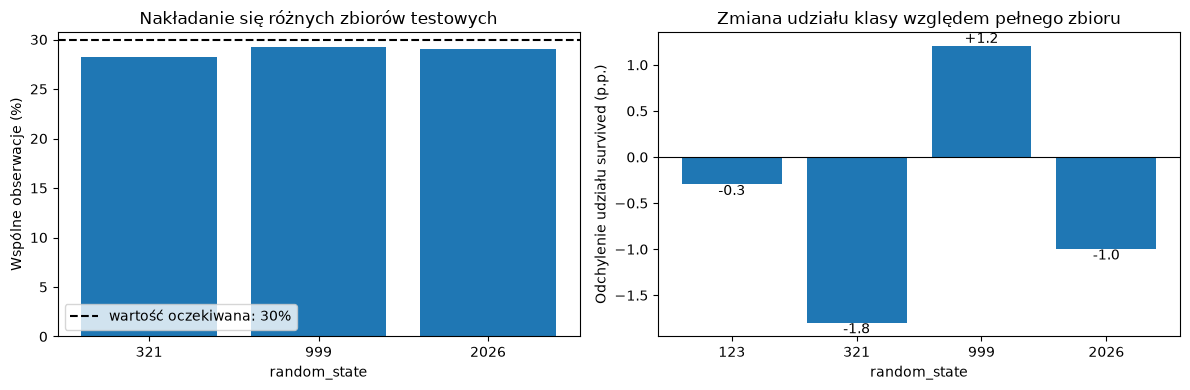

In [76]:
reference_seed = 123
seeds = [123, 321, 999, 2026]
indices = np.arange(len(df))

# Ten sam seed zawsze odtwarza identyczny podział.
_, reference_test_idx = train_test_split(
    indices, test_size=0.3, random_state=reference_seed
)
_, repeated_test_idx = train_test_split(
    indices, test_size=0.3, random_state=reference_seed
)
print("Ten sam random_state daje identyczny test:",
      np.array_equal(reference_test_idx, repeated_test_idx))

rows = []
for seed in seeds:
    _, test_idx = train_test_split(indices, test_size=0.3, random_state=seed)
    test_data = df.iloc[test_idx]
    rows.append({
        "random_state": seed,
        "wspólne obserwacje z seedem 123 (%)": (
            100 * len(np.intersect1d(reference_test_idx, test_idx)) / len(reference_test_idx)
        ),
        "udział osób, które przeżyły": test_data["survived"].mean(),
        "średnia fare": test_data["fare"].mean(),
    })

comparison = pd.DataFrame(rows).round(3)
comparison

# Dla dwóch losowych testów o rozmiarze 30% oczekujemy około 30% wspólnych obserwacji.
comparison_other = comparison.loc[comparison["random_state"] != reference_seed]
full_survived_share = df["survived"].mean()
deviation_pp = 100 * (comparison["udział osób, które przeżyły"] - full_survived_share)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison_other["random_state"].astype(str),
            comparison_other["wspólne obserwacje z seedem 123 (%)"])
axes[0].axhline(30, color="black", linestyle="--", label="wartość oczekiwana: 30%")
axes[0].set_xlabel("random_state")
axes[0].set_ylabel("Wspólne obserwacje (%)")
axes[0].set_title("Nakładanie się różnych zbiorów testowych")
axes[0].legend()

bars = axes[1].bar(comparison["random_state"].astype(str), deviation_pp)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("random_state")
axes[1].set_ylabel("Odchylenie udziału survived (p.p.)")
axes[1].set_title("Zmiana udziału klasy względem pełnego zbioru")
for bar, value in zip(bars, deviation_pp):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, value,
        f"{value:+.1f}", ha="center",
        va="bottom" if value >= 0 else "top",
    )

fig.tight_layout()
plt.show()


#### Wniosek

Różne seedy zmieniają większość obserwacji w zbiorze testowym, choć w tym przykładzie udział klas różni się tylko o kilka punktów procentowych. Dla silnie niezbalansowanej zmiennej docelowej takie wahania mogą być znacznie większe; później poznamy stratyfikację, która pomaga zachować podobny udział klas w częściach danych.

